# Activity No. 1 — Machine Learning Classification and Regression

**Name: Avinash Singh** | **Div:-E** | **Batch:-E1** | **RollNO:- 312** | **PRN: 202401040311**

Github repo :- https://github.com/avinashsingh539/AIML_CA_IA_Labs/tree/main/I.A/Activity_1_Machine_learning_classification_and_regression

**Objective:** Apply supervised machine-learning techniques to hard-drive SMART data through:
1. **Classification:** predict whether a drive has a recorded failure within the next seven calendar days.
2. **Regression:** estimate the number of days until a recorded failure for observations from drives that fail within the observed quarter.

**Input data:** Original Q1 2016 daily CSV files. Set `RAW_DIR` in Section 2 to the folder containing these files. The source files are not modified.

## 1. Problem Definition

### Classification
For a drive observed on date $t$, predict whether a recorded failure occurs during the following seven calendar days:

$$
Y_{7d} = \begin{cases} 
1 & \text{if failure occurs in } (t, t+7] \\
0 & \text{if at least seven days of follow-up are available and no failure occurs} \\
\text{unknown} & \text{if the outcome cannot be observed}
\end{cases}
$$

### Regression
For a drive with a confirmed failure later in the quarter, estimate the Remaining Useful Life ($R_t$):

$$
R_t = \text{failure date} - t
$$

* **Scope:** The regression target is limited to observations $1\text{–}30$ days before a failure recorded in Q1 2016.
* **Censoring:** Drives without an observed failure have censored outcomes and are not assigned a numeric target.

---

**Key Difference:** Classification predicts a discrete class ($0$ or $1$), whereas regression predicts a continuous numerical value (days until failure).


## 2. Imports and configuration

DuckDB is used to combine and process the large CSV collection. Pandas and scikit-learn are used for data analysis, model training and evaluation. Outputs are saved separately from the original files.

In [2]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
import joblib
from IPython.display import display

RANDOM_STATE = 42
CHUNK_NOTE = "DuckDB processes the raw CSV collection; only modelling samples are loaded into pandas."
ROOT = Path(r"D:\T.Y\PEC(AIML)\th activities for ia")
RAW_DIR = ROOT / "data_Q1_2016"
OUTPUT_DIR = ROOT / "data" / "activity1_outputs"
REPORT_DIR = ROOT / "reports" / "activity1_outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

HORIZON_DAYS = 7
REGRESSION_HORIZON_DAYS = 30
NEGATIVE_TO_POSITIVE_SAMPLE_RATIO = 20

print("Project root:", ROOT)
print("Raw data folder:", RAW_DIR)
print("Raw folder exists:", RAW_DIR.exists())
print("Output folder:", OUTPUT_DIR)

Project root: D:\T.Y\PEC(AIML)\th activities for ia
Raw data folder: D:\T.Y\PEC(AIML)\th activities for ia\data_Q1_2016
Raw folder exists: True
Output folder: D:\T.Y\PEC(AIML)\th activities for ia\data\activity1_outputs


## 3. Locate the original Q1 2016 files

The input folder must contain the original daily CSV files. macOS metadata files and temporary files are excluded.

In [3]:
if not RAW_DIR.exists():
    alternatives = [ROOT / "data" / "data_Q1_2016", ROOT / "data" / "raw"]
    found = next((p for p in alternatives if p.exists()), None)
    if found is not None:
        RAW_DIR = found

daily_files = sorted(
    p for p in RAW_DIR.glob("*.csv")
    if p.is_file() and "__macosx" not in str(p).lower()
    and not p.name.startswith("~$")
)
print("Daily CSV files found:", len(daily_files))
if daily_files:
    print("First file:", daily_files[0].name)
    print("Last file:", daily_files[-1].name)
    display_files = pd.DataFrame({
        "file": [p.name for p in daily_files],
        "size_MB": [round(p.stat().st_size / (1024**2), 2) for p in daily_files]
    })
    display(display_files.head(10))
else:
    raise FileNotFoundError(
        f"No original daily CSV files found in {RAW_DIR}. "
        "Update RAW_DIR to the folder containing the Q1 2016 source CSVs."
    )

Daily CSV files found: 91
First file: 2016-01-01.csv
Last file: 2016-03-31.csv


,file,size_MB
0,2016-01-01.csv,14.26
1,2016-01-02.csv,14.26
2,2016-01-03.csv,14.28
3,2016-01-04.csv,14.28
4,2016-01-05.csv,14.27
5,2016-01-06.csv,14.26
6,2016-01-07.csv,14.25
7,2016-01-08.csv,14.25
8,2016-01-09.csv,14.25
9,2016-01-10.csv,14.25


## 4. Combine the original files

The daily records are appended by column name. The union of source columns is preserved; missing fields in individual files remain NULL. No feature selection, imputation or transformation is performed during combination.

The combined data is saved as Parquet because the dataset is larger than an Excel worksheet can hold.

In [4]:
DB_PATH = OUTPUT_DIR / "activity1.duckdb"
RAW_PARQUET = OUTPUT_DIR / "combined_raw_q1_2016.parquet"
con = duckdb.connect(str(DB_PATH))

# Leave room for the operating system; DuckDB can use disk-backed temporary files.
con.execute("SET memory_limit='4GB'")
con.execute("SET threads=4")
TEMP_DIR = OUTPUT_DIR / "duckdb_tmp"
TEMP_DIR.mkdir(parents=True, exist_ok=True)
con.execute(f"SET temp_directory='{(OUTPUT_DIR / 'duckdb_tmp').as_posix()}'")

def sql_string(value):
    return "'" + str(value).replace("'", "''") + "'"

file_list_sql = "[" + ", ".join(sql_string(p.as_posix()) for p in daily_files) + "]"
raw_path_sql = sql_string(RAW_PARQUET.as_posix())

if not RAW_PARQUET.exists():
    con.execute(f'''
        COPY (
            SELECT *
            FROM read_csv({file_list_sql}, union_by_name=true, header=true, auto_detect=true)
        )
        TO {raw_path_sql} (FORMAT PARQUET, COMPRESSION ZSTD)
    ''')
    print("Combined raw Parquet created:", RAW_PARQUET)
else:
    print("Using existing combined raw Parquet:", RAW_PARQUET)

raw_rows = con.execute(f"SELECT COUNT(*) FROM read_parquet({raw_path_sql})").fetchone()[0]
raw_columns = [r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet({raw_path_sql})").fetchall()]
print(f"Combined raw shape: {raw_rows:,} rows × {len(raw_columns)} columns")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Combined raw Parquet created: D:\T.Y\PEC(AIML)\th activities for ia\data\activity1_outputs\combined_raw_q1_2016.parquet
Combined raw shape: 5,467,888 rows × 95 columns


## 5. Inspect the source data

Check the source schema, required fields, number of records, unique drives, date range and available SMART attributes. The `failure` field is used to construct targets and is excluded from predictor inputs.

In [5]:
required = {"date", "serial_number", "failure", "model", "capacity_bytes"}
missing_required = required - set(raw_columns)
if missing_required:
    raise ValueError(f"Required source columns are missing: {sorted(missing_required)}")

schema_df = con.execute(f"DESCRIBE SELECT * FROM read_parquet({raw_path_sql})").df()
display(schema_df.head(30))

smart_columns = [c for c in raw_columns if c.lower().startswith("smart_")]
print("SMART columns:", len(smart_columns))
print("Examples:", smart_columns[:25])

source_summary = con.execute(f'''
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT serial_number) AS unique_drives,
        MIN(CAST(date AS DATE)) AS first_date,
        MAX(CAST(date AS DATE)) AS last_date,
        SUM(CASE WHEN TRY_CAST(failure AS INTEGER)=1 THEN 1 ELSE 0 END) AS failure_rows
    FROM read_parquet({raw_path_sql})
''').df()
display(source_summary)

,column_name,column_type,null,key,default,extra
0,date,DATE,YES,None,None,None
1,serial_number,VARCHAR,YES,None,None,None
2,model,VARCHAR,YES,None,None,None
3,capacity_bytes,BIGINT,YES,None,None,None
4,failure,BIGINT,YES,None,None,None
5,smart_1_normalized,BIGINT,YES,None,None,None
6,smart_1_raw,BIGINT,YES,None,None,None
7,smart_2_normalized,BIGINT,YES,None,None,None
8,smart_2_raw,BIGINT,YES,None,None,None
9,smart_3_normalized,BIGINT,YES,None,None,None


SMART columns: 90
Examples: ['smart_1_normalized', 'smart_1_raw', 'smart_2_normalized', 'smart_2_raw', 'smart_3_normalized', 'smart_3_raw', 'smart_4_normalized', 'smart_4_raw', 'smart_5_normalized', 'smart_5_raw', 'smart_7_normalized', 'smart_7_raw', 'smart_8_normalized', 'smart_8_raw', 'smart_9_normalized', 'smart_9_raw', 'smart_10_normalized', 'smart_10_raw', 'smart_11_normalized', 'smart_11_raw', 'smart_12_normalized', 'smart_12_raw', 'smart_13_normalized', 'smart_13_raw', 'smart_15_normalized']


,total_rows,unique_drives,first_date,last_date,failure_rows
0,5467888,64074,2016-01-01,2016-03-31,336.0


## 6. Select candidate SMART attributes

The initial candidates are SMART 5, 9, 187, 188, 194, 197 and 198. Common interpretations include reallocated sectors (5), power-on hours (9), reported uncorrectable errors (187), command timeouts (188), temperature-related readings (194), current pending sectors (197) and offline uncorrectable sectors (198).

These meanings can vary by manufacturer and model. Raw and vendor-normalized fields are treated as separate inputs and are used only when present in the source data.

In [6]:
SMART_IDS = ["5", "9", "187", "188", "194", "197", "198"]
available_smart = {}
for sid in SMART_IDS:
    raw_name = f"smart_{sid}_raw"
    norm_name = f"smart_{sid}_normalized"
    available_smart[sid] = {
        "raw": raw_name if raw_name in raw_columns else None,
        "normalized": norm_name if norm_name in raw_columns else None
    }

display(pd.DataFrame([
    {"SMART_ID": sid, "raw_available": v["raw"] is not None,
     "normalized_available": v["normalized"] is not None}
    for sid, v in available_smart.items()
]))

,SMART_ID,raw_available,normalized_available
0,5,True,True
1,9,True,True
2,187,True,True
3,188,True,True
4,194,True,True
5,197,True,True
6,198,True,True


## 7. Construct targets and engineer features

The cell creates two targets:

- `failure_next_7_days`: 1 when a failure is recorded strictly after the observation date and within seven days; 0 only when seven days of follow-up are available without a failure; otherwise unknown.
- `days_to_failure_30`: days until a recorded failure, for observations 1–30 days before that event. This target is available only for the observed failure cohort.

Candidate predictor features include capacity in TB, log-transformed non-negative raw SMART values, missing-value indicators, non-zero indicators, historical lags, 1/3/7-day changes and seven-calendar-day rolling means.

Historical features are calculated separately for each drive and use observations on or before the prediction date. The target fields and failure information are not used as predictors.

In [7]:
def qid(name):
    return '"' + str(name).replace('"', '""') + '"'

# Build a narrow base table to reduce memory requirements.
base_exprs = [
    "TRY_CAST(date AS DATE) AS obs_date",
    "CAST(serial_number AS VARCHAR) AS serial_number",
    "CAST(model AS VARCHAR) AS model",
    "TRY_CAST(capacity_bytes AS DOUBLE) AS capacity_bytes",
    "TRY_CAST(failure AS INTEGER) AS failure"
]
raw_ids_used = []
norm_ids_used = []
for sid, fields in available_smart.items():
    if fields["raw"]:
        base_exprs.append(f"TRY_CAST({qid(fields['raw'])} AS DOUBLE) AS {qid(fields['raw'])}")
        raw_ids_used.append(sid)
    if fields["normalized"]:
        base_exprs.append(f"TRY_CAST({qid(fields['normalized'])} AS DOUBLE) AS {qid(fields['normalized'])}")
        norm_ids_used.append(sid)

# Validate duplicate drive-date keys before using time windows.
duplicate_keys = con.execute(f'''
    SELECT COUNT(*) FROM (
        SELECT serial_number, CAST(date AS DATE) AS obs_date, COUNT(*) AS n
        FROM read_parquet({raw_path_sql})
        GROUP BY serial_number, CAST(date AS DATE)
        HAVING COUNT(*) > 1
    )
''').fetchone()[0]
print("Duplicate drive-date groups:", duplicate_keys)
if duplicate_keys > 0:
    raise ValueError("Duplicate drive/date records found. Resolve them before building time-based features.")

base_sql = ",\n            ".join(base_exprs)
feature_path_sql = sql_string((OUTPUT_DIR / "q1_2016_engineered_features.parquet").as_posix())

history_exprs = []
derived_exprs = []
history_helper_columns = []
time_raw_ids = [sid for sid in ["5", "187", "197", "198", "9", "194"] if sid in raw_ids_used]

for sid in time_raw_ids:
    col = f"smart_{sid}_raw"
    # Store historical observations and their dates. Calendar differences are checked below.
    history_exprs.extend([
        f"LAG({qid(col)}, 1) OVER w AS {qid(col + '_prev_obs')}",
        f"LAG(obs_date, 1) OVER w AS {qid(col + '_prev_date')}",
        f"LAG({qid(col)}, 3) OVER w AS {qid(col + '_lag3_rows')}",
        f"LAG(obs_date, 3) OVER w AS {qid(col + '_lag3_date')}",
        f"LAG({qid(col)}, 7) OVER w AS {qid(col + '_lag7_rows')}",
        f"LAG(obs_date, 7) OVER w AS {qid(col + '_lag7_date')}",
        f"AVG({qid(col)}) OVER (PARTITION BY serial_number ORDER BY obs_date RANGE BETWEEN INTERVAL 6 DAYS PRECEDING AND CURRENT ROW) AS {qid(col + '_rolling_mean_7d')}"
    ])
    history_helper_columns.extend([
        col + "_prev_obs", col + "_prev_date", col + "_lag3_rows",
        col + "_lag3_date", col + "_lag7_rows", col + "_lag7_date"
    ])
    derived_exprs.extend([
        f"CASE WHEN date_diff('day', {qid(col + '_prev_date')}, obs_date)=1 THEN {qid(col + '_prev_obs')} END AS {qid(col + '_lag_1d')}",
        f"CASE WHEN date_diff('day', {qid(col + '_prev_date')}, obs_date)=1 THEN {qid(col)} - {qid(col + '_prev_obs')} END AS {qid(col + '_diff_1d')}",
        f"CASE WHEN date_diff('day', {qid(col + '_lag3_date')}, obs_date)=3 THEN {qid(col)} - {qid(col + '_lag3_rows')} END AS {qid(col + '_diff_3d')}",
        f"CASE WHEN date_diff('day', {qid(col + '_lag7_date')}, obs_date)=7 THEN {qid(col)} - {qid(col + '_lag7_rows')} END AS {qid(col + '_diff_7d')}"
    ])

smart_engineered_exprs = [
    "capacity_bytes / 1000000000000.0 AS capacity_tb"
]
for sid in raw_ids_used:
    col = f"smart_{sid}_raw"
    smart_engineered_exprs.extend([
        f"CASE WHEN {qid(col)} >= 0 THEN LN(1 + {qid(col)}) END AS {qid(col + '_log1p')}",
        f"CASE WHEN {qid(col)} IS NULL THEN 1 ELSE 0 END AS {qid(col + '_missing')}"
    ])
for sid in norm_ids_used:
    col = f"smart_{sid}_normalized"
    smart_engineered_exprs.append(f"CASE WHEN {qid(col)} IS NULL THEN 1 ELSE 0 END AS {qid(col + '_missing')}")

critical_ids = [sid for sid in ["5", "187", "188", "197", "198"] if sid in raw_ids_used]
critical_flags = []
for sid in critical_ids:
    col = f"smart_{sid}_raw"
    flag = f"smart_{sid}_raw_positive"
    smart_engineered_exprs.append(
        f"CASE WHEN {qid(col)} IS NULL THEN NULL WHEN {qid(col)} > 0 THEN 1 ELSE 0 END AS {qid(flag)}"
    )
    critical_flags.append(flag)

if critical_ids:
    # Compute the total directly from original raw values. This avoids relying
    # on aliases created earlier in the same SELECT statement.
    sum_flags = " + ".join(
        f"CASE WHEN {qid('smart_' + sid + '_raw')} > 0 THEN 1 ELSE 0 END"
        for sid in critical_ids
    )
    any_observed = " OR ".join(
        f"{qid('smart_' + sid + '_raw')} IS NOT NULL" for sid in critical_ids
    )
    smart_engineered_exprs.append(
        f"CASE WHEN NOT ({any_observed}) THEN NULL ELSE ({sum_flags}) END AS smart_critical_nonzero_count"
    )

smart_engineered_sql = ",\n            ".join(smart_engineered_exprs)
history_sql = ",\n            ".join(history_exprs) if history_exprs else "obs_date AS history_placeholder"
derived_sql = ",\n            ".join(derived_exprs) if derived_exprs else "obs_date AS derived_placeholder"

feature_sql = f'''
COPY (
    WITH base AS (
        SELECT {base_sql}
        FROM read_parquet({raw_path_sql})
        WHERE date IS NOT NULL AND serial_number IS NOT NULL
    ),
    drive_bounds AS (
        SELECT
            serial_number,
            MAX(obs_date) AS last_observed_date,
            MIN(CASE WHEN failure=1 THEN obs_date END) AS failure_date
        FROM base
        GROUP BY serial_number
    ),
    joined AS (
        SELECT b.*, d.last_observed_date, d.failure_date
        FROM base b
        LEFT JOIN drive_bounds d USING (serial_number)
    ),
    history AS (
        SELECT *,
            {history_sql}
        FROM joined
        WINDOW w AS (PARTITION BY serial_number ORDER BY obs_date)
    ),
    engineered AS (
        SELECT
            * EXCLUDE ({", ".join(qid(c) for c in history_helper_columns)}),
            {smart_engineered_sql},
            {derived_sql}
        FROM history
    )
    SELECT *,
        CASE
            WHEN failure_date > obs_date
             AND failure_date <= obs_date + INTERVAL {HORIZON_DAYS} DAYS THEN 1
            WHEN last_observed_date >= obs_date + INTERVAL {HORIZON_DAYS} DAYS THEN 0
            ELSE NULL
        END AS failure_next_7_days,
        CASE
            WHEN failure=0
             AND failure_date > obs_date
             AND failure_date <= obs_date + INTERVAL {REGRESSION_HORIZON_DAYS} DAYS
            THEN date_diff('day', obs_date, failure_date)
            ELSE NULL
        END AS days_to_failure_30
    FROM engineered
)
TO {feature_path_sql} (FORMAT PARQUET, COMPRESSION ZSTD)
'''

if not (OUTPUT_DIR / "q1_2016_engineered_features.parquet").exists():
    con.execute(feature_sql)
    print("Engineered feature table created.")
else:
    print("Using existing engineered feature table. Delete it only if you intentionally want to rebuild.")

Duplicate drive-date groups: 0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Engineered feature table created.


## 8. Review engineered data and target counts

Review the number of known positive, known negative and unknown classification labels, along with the number of regression observations. Unknown classification labels are excluded from classification training because their outcomes cannot be established.

In [8]:
FEATURE_PARQUET = OUTPUT_DIR / "q1_2016_engineered_features.parquet"
feature_path_sql = sql_string(FEATURE_PARQUET.as_posix())

feature_summary = con.execute(f'''
    SELECT
        COUNT(*) AS engineered_rows,
        COUNT(DISTINCT serial_number) AS unique_drives,
        SUM(CASE WHEN failure_next_7_days=1 THEN 1 ELSE 0 END) AS class_positive,
        SUM(CASE WHEN failure_next_7_days=0 THEN 1 ELSE 0 END) AS class_negative,
        SUM(CASE WHEN failure_next_7_days IS NULL THEN 1 ELSE 0 END) AS class_unknown,
        SUM(CASE WHEN days_to_failure_30 IS NOT NULL THEN 1 ELSE 0 END) AS regression_rows,
        MIN(obs_date) AS first_date,
        MAX(obs_date) AS last_date
    FROM read_parquet({feature_path_sql})
''').df()
display(feature_summary)

engineered_columns = [r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet({feature_path_sql})").fetchall()]
print("Engineered table columns:", len(engineered_columns))
display(pd.DataFrame({"engineered_column": engineered_columns}))

,engineered_rows,unique_drives,class_positive,class_negative,class_unknown,regression_rows,first_date,last_date
0,5467888,64074,2169.0,5020309.0,445410.0,8014.0,2016-01-01,2016-03-31


Engineered table columns: 81


,engineered_column
0,obs_date
1,serial_number
2,model
3,capacity_bytes
4,failure
...,...
76,smart_194_raw_diff_1d
77,smart_194_raw_diff_3d
78,smart_194_raw_diff_7d
79,failure_next_7_days


## 9. Classification target distribution

Failure records are rare compared with non-failure records. The chart uses a logarithmic vertical axis so both classes can be seen. The subsequent modelling sample is balanced by sampling non-failure records; sampling weights are retained for evaluation.

,failure_next_7_days,rows
0,0,5020309
1,1,2169


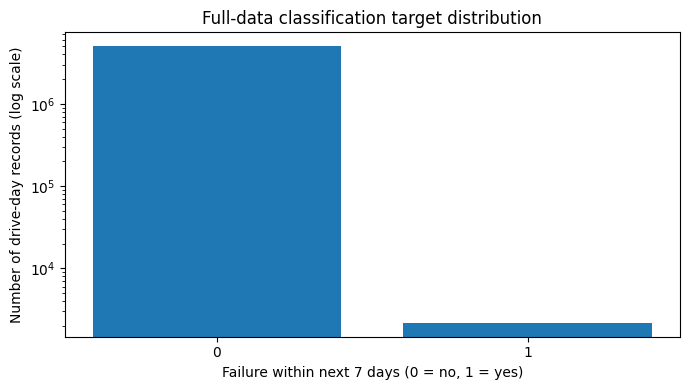

In [9]:
class_counts = con.execute(f'''
    SELECT failure_next_7_days, COUNT(*) AS rows
    FROM read_parquet({feature_path_sql})
    WHERE failure_next_7_days IS NOT NULL
    GROUP BY failure_next_7_days
    ORDER BY failure_next_7_days
''').df()
display(class_counts)

plt.figure(figsize=(7, 4))
plt.bar(class_counts["failure_next_7_days"].astype(str), class_counts["rows"])
plt.yscale("log")
plt.title("Full-data classification target distribution")
plt.xlabel("Failure within next 7 days (0 = no, 1 = yes)")
plt.ylabel("Number of drive-day records (log scale)")
plt.tight_layout()
plt.show()

## 10. Create the classification sample

All positive records with known labels are retained. A reproducible sample of non-failure records is selected, up to 20 negatives per positive. Each sampled negative is assigned a weight based on the full negative count divided by the sampled negative count. These weights are used for evaluation on the original class distribution.

`class_weight="balanced_subsample"` is also used in the Random Forest to address class imbalance during training.

In [10]:
positive_count, negative_count = con.execute(f'''
    SELECT
        SUM(CASE WHEN failure_next_7_days=1 THEN 1 ELSE 0 END),
        SUM(CASE WHEN failure_next_7_days=0 THEN 1 ELSE 0 END)
    FROM read_parquet({feature_path_sql})
''').fetchone()
positive_count = int(positive_count or 0)
negative_count = int(negative_count or 0)
if positive_count < 10 or negative_count < 100:
    raise ValueError("Not enough labelled examples for the classification demonstration.")

n_negative_sample = min(negative_count, max(10000, positive_count * NEGATIVE_TO_POSITIVE_SAMPLE_RATIO))
negative_weight = negative_count / n_negative_sample
CLASS_SAMPLE = OUTPUT_DIR / "classification_sample.parquet"
class_sample_sql = sql_string(CLASS_SAMPLE.as_posix())

if not CLASS_SAMPLE.exists():
    con.execute(f'''
        COPY (
            SELECT *, 1.0 AS sample_weight
            FROM read_parquet({feature_path_sql})
            WHERE failure_next_7_days=1 AND failure=0
            UNION ALL
            SELECT *, {negative_weight} AS sample_weight
            FROM (
                SELECT *
                FROM read_parquet({feature_path_sql})
                WHERE failure_next_7_days=0 AND failure=0
                ORDER BY hash(CAST(serial_number AS VARCHAR) || CAST(obs_date AS VARCHAR))
                LIMIT {n_negative_sample}
            )
        )
        TO {class_sample_sql} (FORMAT PARQUET, COMPRESSION ZSTD)
    ''')
    print("Classification sample saved:", CLASS_SAMPLE)
else:
    print("Using existing classification sample:", CLASS_SAMPLE)

class_df = con.execute(f"SELECT * FROM read_parquet({class_sample_sql})").df()
class_df["obs_date"] = pd.to_datetime(class_df["obs_date"])
print("Classification modelling sample:", class_df.shape)
print("Sample positive rate:", round(class_df["failure_next_7_days"].mean(), 5))
print("Negative population correction weight:", round(negative_weight, 2))
display(class_df[["obs_date", "serial_number", "model", "failure_next_7_days", "sample_weight"]].head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Classification sample saved: D:\T.Y\PEC(AIML)\th activities for ia\data\activity1_outputs\classification_sample.parquet
Classification modelling sample: (45549, 82)
Sample positive rate: 0.04762
Negative population correction weight: 115.73


,obs_date,serial_number,model,failure_next_7_days,sample_weight
0,2016-01-01,PL2331LAGUJLMJ,HGST HMS5C4040ALE640,1,1.0
1,2016-01-02,PL2331LAGUJLMJ,HGST HMS5C4040ALE640,1,1.0
2,2016-01-03,PL2331LAGUJLMJ,HGST HMS5C4040ALE640,1,1.0
3,2016-01-04,PL2331LAGUJLMJ,HGST HMS5C4040ALE640,1,1.0
4,2016-01-05,PL2331LAGUJLMJ,HGST HMS5C4040ALE640,1,1.0


## 11. Classification: chronological split and preprocessing

The classification data is divided chronologically into training, validation and test periods. Seven-day gaps are left between the periods so the future-label windows do not overlap split boundaries.

The date, serial number, current failure flag and target fields are excluded from predictors. Drive model is retained as a categorical candidate. Numerical imputation and categorical encoding are fitted using training data only.

In [11]:
train_end = pd.Timestamp("2016-02-07")
validation_start = pd.Timestamp("2016-02-15")
validation_end = pd.Timestamp("2016-02-21")
test_start = pd.Timestamp("2016-03-01")

# Purge a seven-day gap at each boundary so labels from one split do not use
# failure outcomes occurring inside the next split.
train_df = class_df[class_df["obs_date"] <= train_end].copy()
valid_df = class_df[(class_df["obs_date"] >= validation_start) & (class_df["obs_date"] <= validation_end)].copy()
test_df = class_df[class_df["obs_date"] >= test_start].copy()

def get_predictor_columns(df):
    excluded = {
        "obs_date", "serial_number", "failure", "failure_date", "last_observed_date", "capacity_bytes",
        "failure_next_7_days", "days_to_failure_30", "sample_weight"
    }
    available = [c for c in df.columns if c not in excluded]
    cat = [c for c in ["model"] if c in available]
    num = [c for c in available if c not in cat and pd.api.types.is_numeric_dtype(df[c])]
    return num, cat

numeric_cols, categorical_cols = get_predictor_columns(train_df)

# Quality filtering is learned from training data only.
numeric_cols = [
    c for c in numeric_cols
    if train_df[c].notna().mean() >= 0.02 and train_df[c].nunique(dropna=True) > 1
]
categorical_cols = [
    c for c in categorical_cols
    if train_df[c].nunique(dropna=True) > 1
]

print("Training rows:", len(train_df), "Validation rows:", len(valid_df), "Test rows:", len(test_df))
print("Numeric predictors:", len(numeric_cols))
print("Categorical predictors:", categorical_cols)
print("Purged boundary dates: 2016-02-08 to 2016-02-14 and 2016-02-22 to 2016-02-29")
print("Training positive rate:", round(train_df["failure_next_7_days"].mean(), 5))
print("Validation positive count:", int(valid_df["failure_next_7_days"].sum()))
print("Test positive count:", int(test_df["failure_next_7_days"].sum()))

if train_df["failure_next_7_days"].nunique() < 2 or valid_df["failure_next_7_days"].nunique() < 2 or test_df["failure_next_7_days"].nunique() < 2:
    raise ValueError("At least one chronological split has only one class. Review date boundaries or data coverage.")

X_train = train_df[numeric_cols + categorical_cols]
y_train = train_df["failure_next_7_days"].astype(int)
X_valid = valid_df[numeric_cols + categorical_cols]
y_valid = valid_df["failure_next_7_days"].astype(int)
X_test = test_df[numeric_cols + categorical_cols]
y_test = test_df["failure_next_7_days"].astype(int)

w_valid = valid_df["sample_weight"].to_numpy()
w_test = test_df["sample_weight"].to_numpy()

transformers = []
if numeric_cols:
    transformers.append(("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric_cols))
if categorical_cols:
    transformers.append(("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
classifier = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=160,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

classifier.fit(X_train, y_train)
print("Random Forest classifier training completed.")

Training rows: 19828 Validation rows: 3849 Test rows: 13589
Numeric predictors: 72
Categorical predictors: ['model']
Purged boundary dates: 2016-02-08 to 2016-02-14 and 2016-02-22 to 2016-02-29
Training positive rate: 0.04428
Validation positive count: 159
Test positive count: 721
Random Forest classifier training completed.


## 12. Classification: choose the decision threshold

The Random Forest outputs a score. A threshold converts this score into a class label. The threshold is selected using weighted F1 on the validation period. The final test period is not used to choose the threshold.

In [12]:
valid_prob = classifier.predict_proba(X_valid)[:, 1]
p_valid, r_valid, thresholds = precision_recall_curve(y_valid, valid_prob, sample_weight=w_valid)

if len(thresholds):
    f1_values = 2 * p_valid[:-1] * r_valid[:-1] / np.maximum(p_valid[:-1] + r_valid[:-1], 1e-12)
    best_idx = int(np.nanargmax(f1_values))
    selected_threshold = float(thresholds[best_idx])
else:
    selected_threshold = 0.5

print("Validation-selected threshold:", round(selected_threshold, 6))
print("Validation weighted average precision:", round(average_precision_score(y_valid, valid_prob, sample_weight=w_valid), 6))

Validation-selected threshold: 0.905191
Validation weighted average precision: 0.023528


## 13. Classification: final test evaluation

The final test period is March 2016. Evaluation uses inverse sampling weights to account for the sampled non-failure records. ROC-AUC and average precision measure ranking performance; precision, recall and F1 are reported at the threshold selected on validation data.

,value
ROC_AUC_weighted,0.786793
Average_Precision_weighted,0.036698
Precision_weighted_at_threshold,0.034875
Recall_weighted_at_threshold,0.127601
F1_weighted_at_threshold,0.054778
Balanced_Accuracy_unweighted_sample,0.562945
Selected_threshold,0.905191
Test_sample_rows,13589.000000
Test_positive_rows_in_sample,721.000000


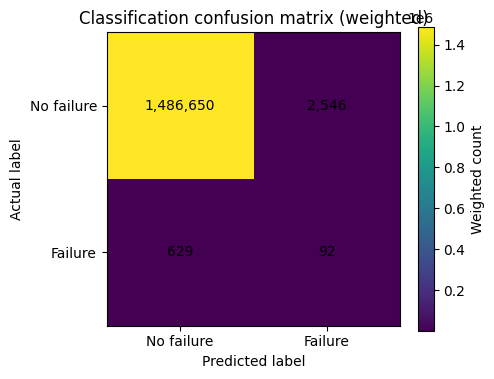

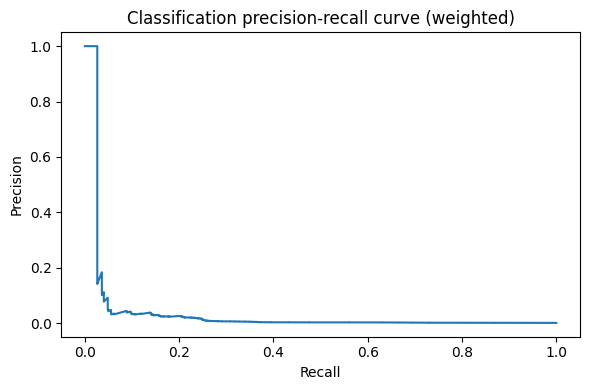

In [13]:
test_prob = classifier.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)

classification_metrics = {
    "ROC_AUC_weighted": roc_auc_score(y_test, test_prob, sample_weight=w_test),
    "Average_Precision_weighted": average_precision_score(y_test, test_prob, sample_weight=w_test),
    "Precision_weighted_at_threshold": precision_score(y_test, test_pred, sample_weight=w_test, zero_division=0),
    "Recall_weighted_at_threshold": recall_score(y_test, test_pred, sample_weight=w_test, zero_division=0),
    "F1_weighted_at_threshold": f1_score(y_test, test_pred, sample_weight=w_test, zero_division=0),
    "Balanced_Accuracy_unweighted_sample": balanced_accuracy_score(y_test, test_pred),
    "Selected_threshold": selected_threshold,
    "Test_sample_rows": int(len(test_df)),
    "Test_positive_rows_in_sample": int(y_test.sum())
}
display(pd.DataFrame([classification_metrics]).T.rename(columns={0:"value"}))

cm = confusion_matrix(y_test, test_pred, sample_weight=w_test)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Classification confusion matrix (weighted)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, f"{value:,.0f}", ha="center", va="center")
plt.xticks([0, 1], ["No failure", "Failure"])
plt.yticks([0, 1], ["No failure", "Failure"])
plt.colorbar(label="Weighted count")
plt.tight_layout()
plt.show()

p_test, r_test, _ = precision_recall_curve(y_test, test_prob, sample_weight=w_test)
plt.figure(figsize=(6, 4))
plt.plot(r_test, p_test)
plt.title("Classification precision-recall curve (weighted)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()

## 14. Classification: feature importance

Permutation importance measures the change in validation average precision when one input feature is shuffled:

\[
I_j=AP_{original}-AP_{shuffled(j)}
\]

A larger positive decrease indicates that the fitted model used that feature for validation ranking. This is model-specific importance, not evidence of causation. Importance is calculated on a validation subset to limit computation.

,feature,importance_mean,importance_std
16,smart_197_raw_rolling_mean_7d,0.045458,0.003662
46,smart_198_raw_positive,0.043945,0.003600
12,smart_198_raw,0.040966,0.000360
33,smart_198_raw_log1p,0.039838,0.000229
31,smart_197_raw_log1p,0.039673,0.003731
10,smart_197_raw,0.039539,0.003753
45,smart_197_raw_positive,0.039368,0.000230
17,smart_198_raw_rolling_mean_7d,0.038637,0.000366
47,smart_critical_nonzero_count,0.036576,0.002920
26,smart_187_raw_missing,0.022820,0.006332


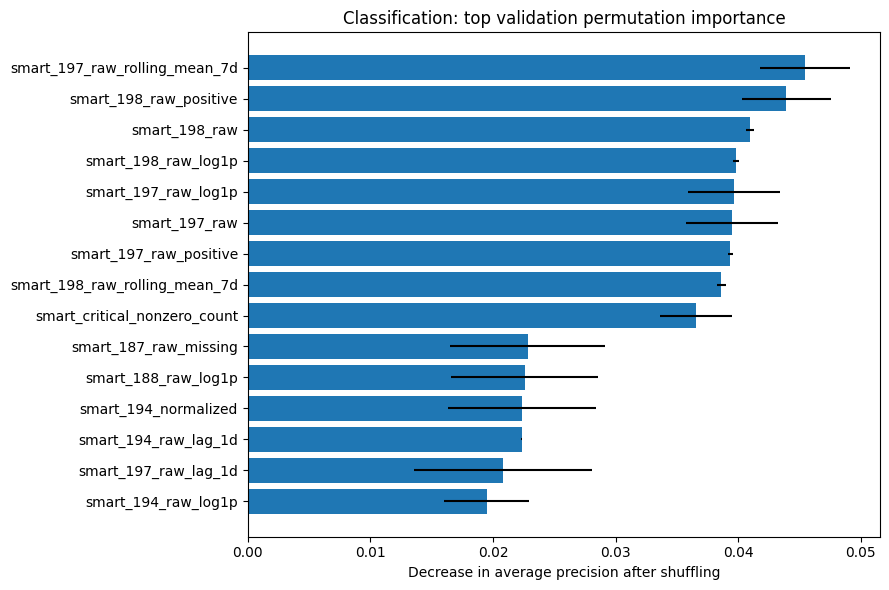

In [14]:
perm_rows = min(3000, len(X_valid))
X_perm = X_valid.sample(n=perm_rows, random_state=RANDOM_STATE) if len(X_valid) > perm_rows else X_valid
y_perm = y_valid.loc[X_perm.index]
w_perm = valid_df.loc[X_perm.index, "sample_weight"].to_numpy()

perm_result = permutation_importance(
    classifier, X_perm, y_perm,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    sample_weight=w_perm
)
class_importance = pd.DataFrame({
    "feature": X_perm.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(class_importance.head(15))
top_imp = class_importance.head(15).sort_values("importance_mean")
plt.figure(figsize=(9, 6))
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.title("Classification: top validation permutation importance")
plt.xlabel("Decrease in average precision after shuffling")
plt.tight_layout()
plt.show()

## 15. Regression: define the target

`days_to_failure_30` is the number of days from an observation to a confirmed failure, restricted to 1–30 days. The target is available only for drives with a failure recorded during Q1 2016. Drives without an observed failure are censored and are excluded from this regression task.

In [15]:
REG_SAMPLE_LIMIT = 100_000
reg_df = con.execute(f'''
    SELECT *
    FROM read_parquet({feature_path_sql})
    WHERE days_to_failure_30 BETWEEN 1 AND {REGRESSION_HORIZON_DAYS}
      AND failure=0
    ORDER BY hash(CAST(serial_number AS VARCHAR) || CAST(obs_date AS VARCHAR))
    LIMIT {REG_SAMPLE_LIMIT}
''').df()

reg_df["obs_date"] = pd.to_datetime(reg_df["obs_date"])
print("Regression cohort rows:", len(reg_df))
print("Distinct failed drives represented:", reg_df["serial_number"].nunique())
display(reg_df["days_to_failure_30"].describe().to_frame("days_to_failure_30"))
if len(reg_df) < 100 or reg_df["serial_number"].nunique() < 5:
    raise ValueError("Insufficient regression cohort. Consider a longer historical period or a different numeric regression target.")

Regression cohort rows: 8014
Distinct failed drives represented: 331


,days_to_failure_30
count,8014.000000
mean,14.512603
std,8.638880
min,1.000000
25%,7.000000
50%,14.000000
75%,22.000000
max,30.000000


## 16. Regression: group-based split

A drive identifier is assigned entirely to either the training set or the test set. This prevents observations from the same physical drive appearing in both sets.

In [16]:
reg_numeric_cols, reg_cat_cols = get_predictor_columns(reg_df)
reg_numeric_cols = [
    c for c in reg_numeric_cols
    if reg_df[c].notna().mean() >= 0.02 and reg_df[c].nunique(dropna=True) > 1
]
reg_cat_cols = [c for c in reg_cat_cols if reg_df[c].nunique(dropna=True) > 1]
reg_features = reg_numeric_cols + reg_cat_cols

groups = reg_df["serial_number"].astype(str)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
reg_train_idx, reg_test_idx = next(splitter.split(reg_df[reg_features], reg_df["days_to_failure_30"], groups=groups))

Xr_train = reg_df.iloc[reg_train_idx][reg_features]
yr_train = reg_df.iloc[reg_train_idx]["days_to_failure_30"].astype(float)
Xr_test = reg_df.iloc[reg_test_idx][reg_features]
yr_test = reg_df.iloc[reg_test_idx]["days_to_failure_30"].astype(float)

print("Regression training rows:", len(Xr_train))
print("Regression test rows:", len(Xr_test))
print("Train drives:", reg_df.iloc[reg_train_idx]["serial_number"].nunique())
print("Test drives:", reg_df.iloc[reg_test_idx]["serial_number"].nunique())

reg_transformers = []
if reg_numeric_cols:
    reg_transformers.append(("numeric", SimpleImputer(strategy="median", add_indicator=True), reg_numeric_cols))
if reg_cat_cols:
    reg_transformers.append(("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), reg_cat_cols))
reg_preprocessor = ColumnTransformer(transformers=reg_transformers, remainder="drop")

regressor = Pipeline([
    ("preprocess", reg_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=140,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
regressor.fit(Xr_train, yr_train)
print("Random Forest regressor training completed.")

Regression training rows: 6151
Regression test rows: 1863
Train drives: 248
Test drives: 83
Random Forest regressor training completed.


## 17. Regression: evaluation metrics

Regression predictions are evaluated using:

\[
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
\]

\[
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
\]

\[
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
\]

MAE and RMSE are measured in days; lower values indicate smaller prediction errors. R² compares the model with a baseline that predicts the test-set mean and can be negative.

,value
RandomForest_MAE_days,7.553798
RandomForest_RMSE_days,9.247504
RandomForest_R2,-0.169670
MedianBaseline_MAE_days,7.374665
MedianBaseline_RMSE_days,8.553234
Regression_test_rows,1863.000000
Regression_test_drives,83.000000


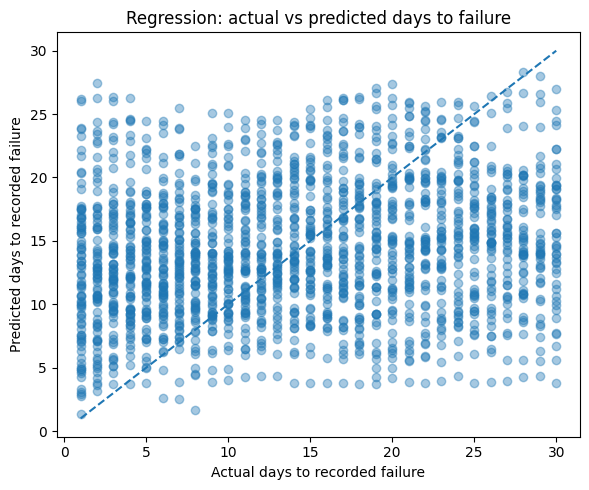

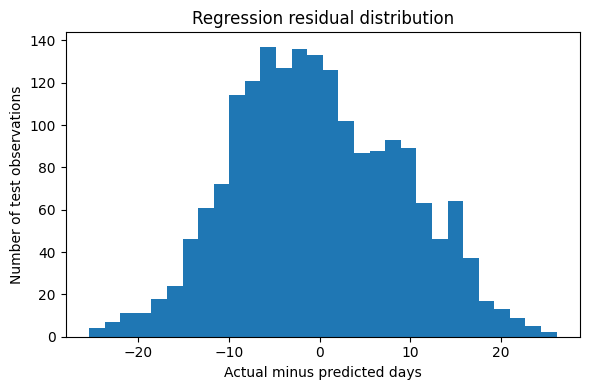

In [17]:
reg_pred = regressor.predict(Xr_test)
dummy = DummyRegressor(strategy="median")
dummy.fit(Xr_train, yr_train)
dummy_pred = dummy.predict(Xr_test)

regression_metrics = {
    "RandomForest_MAE_days": mean_absolute_error(yr_test, reg_pred),
    "RandomForest_RMSE_days": mean_squared_error(yr_test, reg_pred) ** 0.5,
    "RandomForest_R2": r2_score(yr_test, reg_pred),
    "MedianBaseline_MAE_days": mean_absolute_error(yr_test, dummy_pred),
    "MedianBaseline_RMSE_days": mean_squared_error(yr_test, dummy_pred) ** 0.5,
    "Regression_test_rows": int(len(yr_test)),
    "Regression_test_drives": int(reg_df.iloc[reg_test_idx]["serial_number"].nunique())
}
display(pd.DataFrame([regression_metrics]).T.rename(columns={0:"value"}))

plt.figure(figsize=(6, 5))
plt.scatter(yr_test, reg_pred, alpha=0.4)
low = min(float(yr_test.min()), float(reg_pred.min()))
high = max(float(yr_test.max()), float(reg_pred.max()))
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Regression: actual vs predicted days to failure")
plt.xlabel("Actual days to recorded failure")
plt.ylabel("Predicted days to recorded failure")
plt.tight_layout()
plt.show()

residuals = yr_test.to_numpy() - reg_pred
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=30)
plt.title("Regression residual distribution")
plt.xlabel("Actual minus predicted days")
plt.ylabel("Number of test observations")
plt.tight_layout()
plt.show()

## 18. Compare classification and regression

Classification predicts a category and is evaluated with classification metrics. Regression predicts a numerical number of days and is evaluated with error metrics. The two results use different target definitions and populations, so their metrics should not be compared directly.

In [18]:
comparison_rows = [
    {"task": "Classification", "target": "Failure within next 7 days", **classification_metrics},
    {"task": "Regression", "target": "Days to recorded failure (1–30 days)", **regression_metrics}
]
# Display the two results separately to avoid mixing metrics with different units.
display(pd.DataFrame([classification_metrics], index=["Classification"]))
display(pd.DataFrame([regression_metrics], index=["Regression"]))

,ROC_AUC_weighted,Average_Precision_weighted,Precision_weighted_at_threshold,Recall_weighted_at_threshold,F1_weighted_at_threshold,Balanced_Accuracy_unweighted_sample,Selected_threshold,Test_sample_rows,Test_positive_rows_in_sample
Classification,0.786793,0.036698,0.034875,0.127601,0.054778,0.562945,0.905191,13589,721


,RandomForest_MAE_days,RandomForest_RMSE_days,RandomForest_R2,MedianBaseline_MAE_days,MedianBaseline_RMSE_days,Regression_test_rows,Regression_test_drives
Regression,7.553798,9.247504,-0.16967,7.374665,8.553234,1863,83


## 19. Save models and results

The outputs include the combined raw data, engineered feature table, classification sample, trained model pipelines, feature-importance table, evaluation metrics and regression test predictions. Original source CSV files are not overwritten.

In [19]:
joblib.dump(classifier, OUTPUT_DIR / "classification_model.joblib")
joblib.dump(regressor, OUTPUT_DIR / "regression_model.joblib")
class_importance.to_csv(REPORT_DIR / "classification_permutation_importance.csv", index=False)

reg_predictions = pd.DataFrame({
    "serial_number": reg_df.iloc[reg_test_idx]["serial_number"].to_numpy(),
    "actual_days_to_failure": yr_test.to_numpy(),
    "predicted_days_to_failure": reg_pred
})
reg_predictions.to_csv(REPORT_DIR / "regression_test_predictions.csv", index=False)

all_metrics = {
    "classification": {k: float(v) if isinstance(v, (np.floating, float, int, np.integer)) else v
                       for k, v in classification_metrics.items()},
    "regression": {k: float(v) if isinstance(v, (np.floating, float, int, np.integer)) else v
                   for k, v in regression_metrics.items()},
    "configuration": {
        "classification_horizon_days": HORIZON_DAYS,
        "regression_horizon_days": REGRESSION_HORIZON_DAYS,
        "negative_to_positive_sample_ratio": NEGATIVE_TO_POSITIVE_SAMPLE_RATIO,
        "random_state": RANDOM_STATE,
        "classification_train_end": str(train_end.date()),
        "classification_validation_end": str(validation_end.date())
    }
}
(REPORT_DIR / "activity1_metrics.json").write_text(json.dumps(all_metrics, indent=2), encoding="utf-8")
print("Models and reports saved.")
print("Output data:", OUTPUT_DIR)
print("Reports:", REPORT_DIR)

Models and reports saved.
Output data: D:\T.Y\PEC(AIML)\th activities for ia\data\activity1_outputs
Reports: D:\T.Y\PEC(AIML)\th activities for ia\reports\activity1_outputs


## 20. Conclusion

This activity applies both classification and regression to Backblaze hard-drive telemetry. The classification model predicts whether a recorded failure occurs within the next seven days. The regression model estimates days until a recorded failure for observations from drives that fail within the quarter.

The workflow includes data combination, data inspection, target construction, feature engineering, preprocessing, model training, evaluation and visualization. Classification is evaluated using ROC-AUC, average precision, precision, recall, F1-score and a confusion matrix. Regression is evaluated using MAE, RMSE and R², with a median baseline for comparison.

The regression task is limited to the observed failure cohort; it does not estimate remaining life for every drive. The results are an educational analysis of Q1 2016 data and require validation on additional periods before practical use.